### Import necessary libraries and Data processing

---



* This cell imports the Pandas library and gives it the alias pd. Pandas is used for working with data, such as creating and manipulating DataFrames and reading CSV files.

In [ ]:
import pandas as pd

* This cell allows the program to create and display graphs, charts, and other visualisations.

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
# Mount drive which is required when you need to read local files within this notebook
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


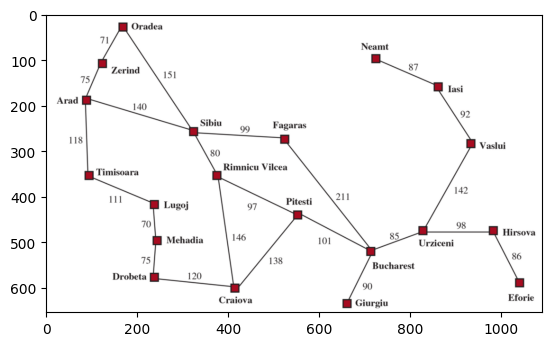

In [ ]:
# Display the state graph in the given Romania problem using function imread() and imshow() in the pyplot module.
img = plt.imread('/content/gdrive/MyDrive/IntroAILab2026/Lab1/images/Romania-map.PNG')
plt.imshow(img)

* This cell loads the cities_coordinates.csv file into a Pandas DataFrame called df_cities.

* The dataset contains information about the cities and their coordinates, which can be used later to create the cities dictionary.

In [ ]:
df_cities = pd.read_csv('/content/gdrive/MyDrive/IntroAILab2026/Lab1/data/cities_coordinates.csv' )
df_cities.head()

* This cell reads the cities_correlation_matrix.csv file into a Pandas DataFrame called df_matrix and then displays the first five rows of the dataset using .head().

In [ ]:
df_matrix = pd.read_csv("/content/gdrive/MyDrive/IntroAILab2026/Lab1/data/cities_correlation_matrix.csv")
df_matrix.head()

This cell creates a dictionary called cities where each city name is stored as a key and its corresponding (X, Y) coordinates are stored as the value. It extracts the relevant columns from df_cities, combines the X and Y coordinates using zip(), and then loops through each city to add the name and coordinates to the dictionary.

In [ ]:
import pandas as pd

df_cities = pd.read_csv('/content/gdrive/MyDrive/IntroAILab2026/Lab1/data/cities_coordinates.csv')

# Define an empty dictionary 'cities'
cities = {}

# Extract the LocationName, LocationX and LocationY columns from the dataframe 'df_cities' and save them as 'name', locationX and locationY, respectively

name = df_cities["LocationName"]
locationX = df_cities["LocationX"]
locationY = df_cities["LocationY"]

# Create a series of city coordinates by using zip() function and x and y cooridnates (locationX and locationY).
'''
The zip() function in Python is used to combine multiple iterables (like lists or tuples) element-wise.
'''
location = zip(locationX, locationY)


# Populate the dictionary 'cities' by using a for-loop and method update()to add elements with each element being 'city name: city location'.
'''
The update() method is used to add or update key-value pairs in a dictionary.
It takes another dictionary or an iterable of key-value pairs (like a list of tuples) and merges it into the existing dictionary.
'''

for x1,x2 in zip(name, location):
    cities.update({x1:x2})

# View content of dictionary cities
cities

NameError: name 'df_cities' is not defined

## Implementation of the Uniform cost search (UCS) algorithm and how it works

How the UCS Algorithm Works

* Step 1: The algorithm creates a visited set to keep track of nodes that have already been explored.

* Step 2: A priority queue is created to store the current node, the path used to reach it, and the total path cost.

* Step 3: The start node is added to the priority queue with a cost of 0.

* Step 4: The algorithm enters a while loop and continues searching until the goal is found or the frontier becomes empty.

* Step 5: The node with the lowest total path cost is removed from the priority queue and selected for expansion.

* Step 6: The selected node is checked against the visited set. If it has already been visited, it is skipped; otherwise, it is added to the visited set.

* Step 7: The algorithm checks whether the selected node is the goal. If it is, the current path is returned and the search terminates.

* Step 8: If the selected node is not the goal, its neighbouring nodes are discovered and added to the frontier if they have not already been visited.

* Step 9: The total cost of each new path is calculated using nx.path_weight(), and the paths are prioritised by their cumulative cost.

* Step 10: The process repeats, always selecting the node with the lowest cumulative path cost, until the goal is reached.

* UCS returns the least-cost path from the start city to the goal city. If no path exists, it returns None.

In [ ]:
def ucs_path(G, start, goal):
    """Find a path from start to goal using uniform cost Search."""

    # Check the start node
    print('start node: {}'.format(start))

    # Initialise a priority queue object to be the frontier -- an empty priority list
    pq = PriorityQueue()

    # Initialise the frontier by the start location and its path
    pq.push((start,[start]),0)
    print('Initialise the frontier as:\n{}\n'.format(pq.returnElements()))

    # initialise the explored set to be an empty set
    visited = set()
    print('Initialise the closed set: {}\n'.format(visited))

    index = 0
    while pq:
        print('Iteration {}'.format(index))

        # Check the frontier before expansion
        print('A new expansion. \nElements in the frontier before expansions: {}\n'.format(pq.returnElements()))

        # Check the node chosen to expand
        print('Node chosen to expand: {}\n'. format(pq.peek()))

        print('Remove the to-be-expanded node from the frontier.')
        (vertex, path) = pq.pop()
        index = index +1

        # Check the frontier after removing a node to expand
        if not (pq.is_empty()):
            print('Elements in the frontier after removing the to-be expanded node {}: \n{}\n'.format(vertex,pq.returnElements()))
        else: print("Frontier after removing the to-be expanded node {} is empty.\n".format(vertex))

        if vertex in visited:
            print('The chosen node is in the closed set. No need to add it to the closed set again.\n')
            continue
        visited.add(vertex)

        # Check the closed set again after adding a node
        print('Elements in the closed set after adding a node {}:{}\n'.format(vertex, visited))

        if vertex == goal:  #late goal check
           print("The goal is found and the number of node expansions is: {}".format(index))
           return path
        else:
           print('The chosen node {} is not the goal.\n'.format(vertex))

        print('Expand the chosen node by adding its neighbour nodes {} to the frontier.\n'.format(list(G.neighbors(vertex))))

        for neighbor in G[vertex]:
            print("neighbor is ", neighbor)
            if neighbor in visited:
                print('The chosen node is in the closed set. No need to add it to the frontier again.\n')
                continue

            pq.push((neighbor, path + [neighbor]),nx.path_weight(G, path + [neighbor],'weight'))

            # Check the frontier after adding a node
            print('Elements in the frontier after adding a neighbour node {}:\n{}\n'.format(neighbor,pq.returnElements()))

    return None  # Return None if no path is found
